# Figure 2B - The excluded-volume landscape (schematic)

Lotthammer, J. M. & Holehouse, A. S. *Disentangling folding from energetic traps in simulations of disordered proteins.* **J. Chem. Inf. Model.** (2025). doi:[10.1021/acs.jcim.4c02005](https://doi.org/10.1021/acs.jcim.4c02005)

**What the figure shows.** Panel B of Figure 2: the same hypothetical disordered protein as Figure 1B, but in the *excluded-volume (EV) limit* - a reference model in which residues cannot overlap but experience no other interactions. The landscape keeps the same rough shape but its barriers are much lower, because nothing but sterics is holding the chain in any one basin.

**Why it matters for PENGUIN.** The EV limit is the reference state that every PENGUIN comparison is made against: it is the most conformationally heterogeneous ensemble a given sequence can have. A residue whose φ/ψ distribution looks like the EV limit is sampling as freely as it possibly can; a residue that deviates from it is being restricted by the full Hamiltonian, and the rest of the pipeline is about deciding whether that restriction is real structure or an energetic trap.

**How it is made.** As in Figure 1, the surface is a sum of random Gaussians; the barrier heights are then clipped so that no region rises far above the wells. Panels A, C and D of Figure 2 are schematics drawn in a vector graphics editor and are not reproduced here. The published figure used the legacy `np.random.seed(123456)`; an explicit generator is used here, so bump placement differs.

## Setup

All notebooks in this directory share `penguin_helpers.py`, a thin layer over SOURSOP's public `soursop.sssampling.SamplingQuality` API that handles data discovery, the manuscript's matplotlib style, and the four-panel PENGUIN figure. The trajectories (~6 GB) live in `data/`, one folder per system with `full/` and `ev/` replicates (see `data/README.md`); they are too large for the SOURSOP repository, so set `PENGUIN_DATA_DIR` if you keep them elsewhere.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms

from penguin_helpers import set_manuscript_style, figure_path, gaussian_noise

set_manuscript_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

## Build and flatten the landscape

In [2]:
rng = np.random.default_rng(123456)

x = np.linspace(0, 100, 500)
y = np.linspace(0, 100, 500)
X, Y = np.meshgrid(x, y)

Z_ev = np.full(X.shape, 10.0)
Z_ev += gaussian_noise(X, Y, gaussians_per_axis=4, height_range=(-6, -4), width_range=(5, 9), rng=rng)
Z_ev += gaussian_noise(X, Y, gaussians_per_axis=15, height_range=(-5, 3), width_range=(4, 5), rng=rng)

# lower the barriers: clip the high ground back to the baseline and deepen the wells slightly
Z_ev[Z_ev > 12] = 10
Z_ev[(Z_ev < 2) | ((Z_ev > 4) & (Z_ev < 6))] -= 1
Z_ev[Z_ev < 0] = 0

## Plot

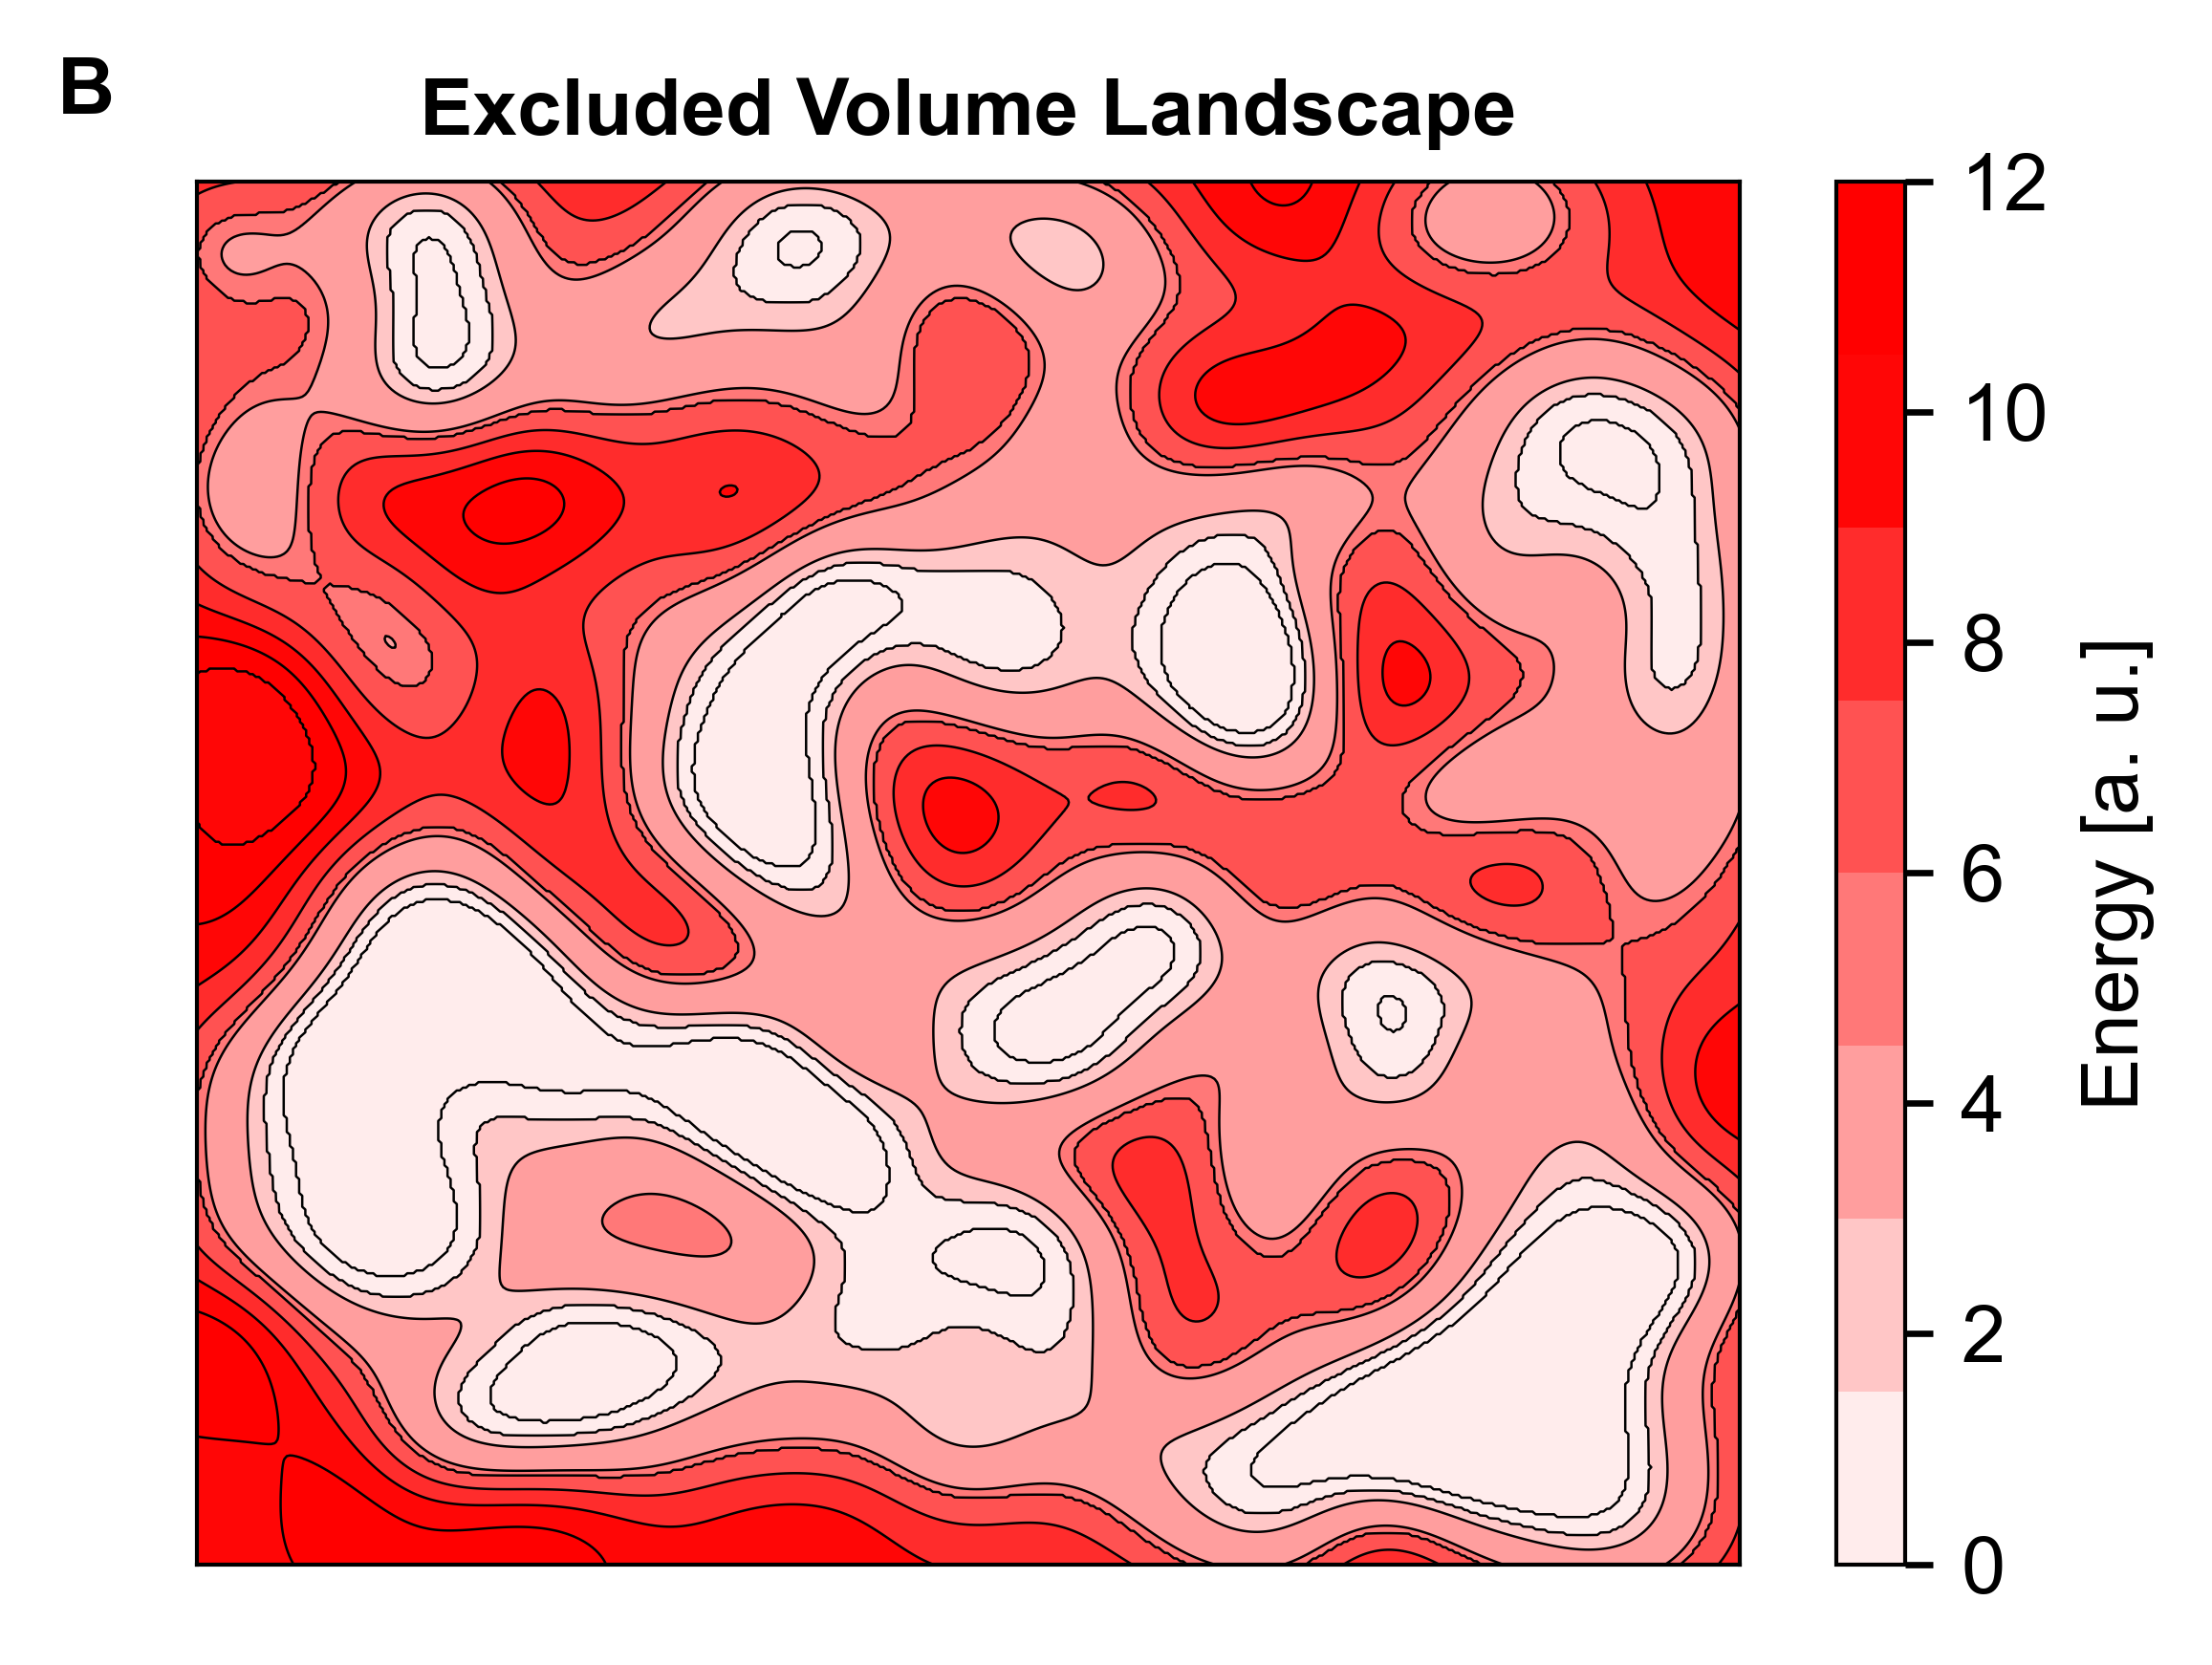

In [3]:
fontsize = 10
fig, ax = plt.subplots(figsize=(4, 3), facecolor="w", dpi=300)

cf = ax.contourf(X, Y, Z_ev, 10, cmap="bwr", vmin=-10, vmax=10)
ax.contour(X, Y, Z_ev, 10, colors="black", linewidths=0.3)
ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Excluded Volume Landscape", fontweight="bold", fontsize=fontsize)
fig.colorbar(cf, label="Energy [a. u.]", ticks=np.arange(0, 14, 2))

trans = mtransforms.ScaledTranslation(-20 / 72, 7 / 72, fig.dpi_scale_trans)
ax.text(0.05, 1.05, "B", transform=ax.transAxes + trans,
        fontsize=fontsize, fontweight="bold", va="top", ha="right")
fig.tight_layout()
fig.savefig(figure_path("fig2", "ev_landscape.pdf"), dpi=300)